# Minimap2 Read Mapping

Run the minimap2 mapper on an artificial reference with known read starts and compare its primary placements with those starts.

The mapper selects anchors, chains consistent hits and extends them into alignments. The input below deliberately avoids real biological material. A random reference also removes many of the repeats that make real mapping ambiguous.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from genome_methods import rng_dna
import mappy as mp

## Worked example

Run the example from top to bottom. The printed check and figure use the same observations.

Mapped 22/22 | starts within 3 bp 22/22


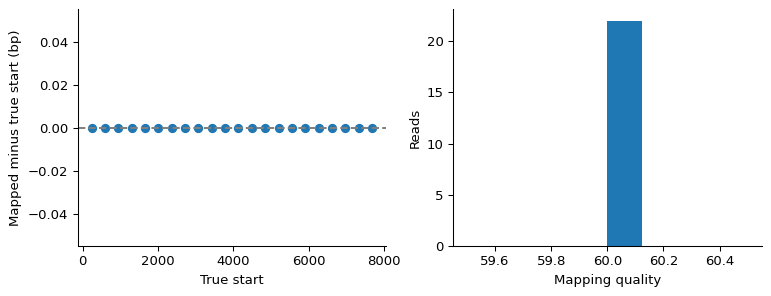

In [2]:
rng = np.random.default_rng(17)
ref = rng_dna(rng, 9000)
aligner = mp.Aligner(seq=ref, preset="map-ont", n_threads=1)
truth = np.arange(233, 7900, 355)
found = []
errors = []
mq = []
for i in truth:
    read = list(ref[i : i + 420])
    for pos in rng.choice(len(read), 8, replace=False):
        read[pos] = next(c for c in "ACGT" if c != read[pos])
    hits = [h for h in aligner.map("".join(read)) if h.is_primary]
    if hits:
        h = hits[0]
        found.append(i)
        errors.append(h.r_st - i)
        mq.append(h.mapq)
print(
    f"Mapped {len(found)}/{len(truth)} | starts within 3 bp {sum(abs(x)<=3 for x in errors)}/{len(truth)}"
)
assert found and np.median(abs(np.array(errors))) <= 3
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3), constrained_layout=True)
a.scatter(found, errors)
a.axhline(0, ls="--", color="0.5")
a.set(xlabel="True start", ylabel="Mapped minus true start (bp)")
b.hist(mq, bins=8)
b.set(xlabel="Mapping quality", ylabel="Reads")
plt.show()

## Interpreting the result

A few terminal errors can be soft-clipped, which shifts the reported start. Mapping quality measures confidence in placement and is different from base quality.

## Exercise

Copy a long segment to a second reference location and compare the number of primary placements and their mapping qualities.

## References

[Li, Minimap2 (2018)](https://doi.org/10.1093/bioinformatics/bty191)

[Minimap2 Python bindings](https://github.com/lh3/minimap2/tree/master/python)

[Roberts et al., minimisers in biological sequence comparison (2004)](https://doi.org/10.1093/bioinformatics/bth408)